# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: Before looking at the data, I predict that women, children, and first-class passengers were more likely to survive. Historical accounts of the Titanic disaster often state that women and children were given priority when lifeboats were loaded. I also think first-class passengers may have had better access to lifeboats. I predict that adult men in third class were less likely to survive. Third-class passengers were farther from the boat deck, and adult men were often given lower priority during evacuation. I do not have a strong prediction for embarkation port, but I expect some differences between groups. I also think passengers traveling with a small family may have had better survival rates than passengers traveling alone or in very large groups.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
# Display the missing-value count for each feature.
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: Each row represents one Titanic passenger. The target feature is Survived, where 0 means the passenger did not survive and 1 means the passenger survived. The dataset contains 891 passengers and 12 features. Most features have no missing values. However, Age has 177 missing values, Cabin has 687 missing values, and Embarked has 2 missing values. Since this lab focuses on categorical comparisons, Age will need to be grouped into categories before it is compared with survival.


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative | int64 | 0 |
| `SibSp` | Quantitative | int64 | 0 |
| `Embarked` | Categorical | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child | Age < 13 | Children were often treated differently during evacuation. |
| Teen | 13 ≤ Age < 18 | Teenagers are distinct from young children and adults. |
| Adult | 18 ≤ Age < 65 | Most passengers fall into this group. |
| Older Adult | Age ≥ 65 | Older passengers may have faced different challenges during evacuation. |
| Unknown | Age is missing (NaN) | Keeps missing ages separate instead of guessing a group. |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: These age groups are reasonable because they represent different stages of life and are easy to interpret. The groups cover all known ages without overlapping. I will keep missing ages in an "Unknown" category rather than guessing a passenger's age group. This avoids introducing errors and keeps the analysis based only on recorded data.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [32]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 13, "age_group"] = "Child"

titanic_df.loc[
    (titanic_df["Age"] >= 13) & (titanic_df["Age"] < 18),
    "age_group"
] = "Teen"

titanic_df.loc[
    (titanic_df["Age"] >= 18) & (titanic_df["Age"] < 65),
    "age_group"
] = "Adult"

titanic_df.loc[titanic_df["Age"] >= 65, "age_group"] = "Older Adult"

titanic_df["age_group"].value_counts()


age_group
Adult          590
Unknown        177
Child           69
Teen            44
Older Adult     11
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [58]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print(titanic_df["Parch"].value_counts().sort_index())
print()

print(titanic_df["SibSp"].value_counts().sort_index())

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: For Parch, I will use three groups: 0, 1-2, and 3 or more. Most passengers have 0, 1, or 2 parents/children aboard, while the larger values are rare. For SibSp, I will use three groups: 0, 1-2, and 3 or more. Most passengers have 0 or 1 sibling/spouse aboard, and the higher values have relatively few observations. I will not exclude any passengers based on these variables because there are no missing values. For Embarked, I will keep missing values as an "Unknown" category rather than guessing a port. When comparing survival rates, the denominator will be the total number of passengers within each category. For example, the survival rate for a group will be the number who survived divided by the total number of passengers in that group.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [83]:
# Create and display the count cross-tab.
age_crosstab = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"]
)

age_crosstab

Survived,0,1
age_group,,
Adult,362,228
Child,29,40
Older Adult,10,1
Teen,23,21
Unknown,125,52


In [84]:
# Calculate conditional percentages and display only the survived column.
age_percent = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

age_percent[[1]]

Survived,1
age_group,
Adult,38.644068
Child,57.971014
Older Adult,9.090909
Teen,47.727273
Unknown,29.378531


For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [85]:
# Display joint percentages, then create a count chart in a separate cell.
age_joint = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="all"
) * 100

age_joint

Survived,0,1
age_group,,
Adult,40.628507,25.589226
Child,3.254770,4.489338
Older Adult,1.122334,0.112233
Teen,2.581369,2.356902
Unknown,14.029181,5.836139


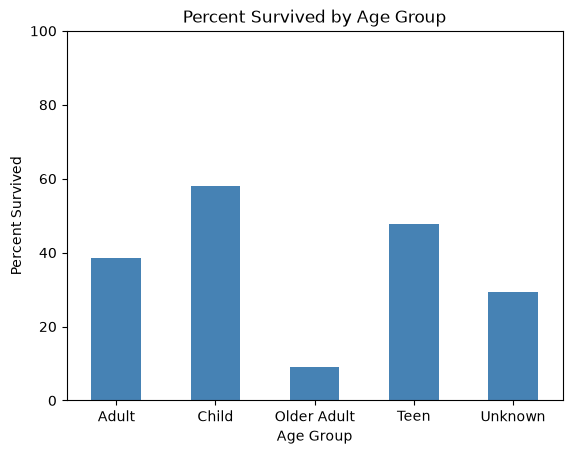

In [86]:
# Plot the conditional percentage who survived.
age_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [107]:
# Create and display the count cross-tab.
sex_crosstab = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"]
)

sex_crosstab

Survived,0,1
Sex,,
female,81,233
male,468,109


In [108]:
# Calculate conditional percentages and display only the survived column.
sex_percent = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sex_percent[[1]]

Survived,1
Sex,
female,74.203822
male,18.890815


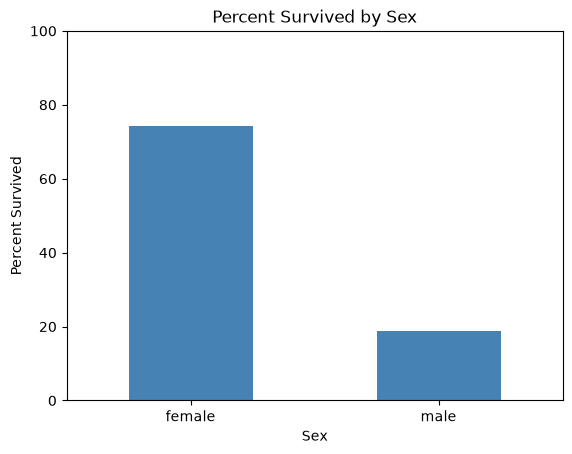

In [109]:
# Plot the conditional percentage who survived.
sex_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Sex")
plt.xlabel("Sex")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [128]:
# Create and display the count cross-tab.
pclass_crosstab = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"]
)

pclass_crosstab

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [129]:
# Calculate conditional percentages and display only the survived column.
pclass_percent = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"],
    normalize="index"
) * 100

pclass_percent[[1]]

Survived,1
Pclass,
1,62.962963
2,47.282609
3,24.236253


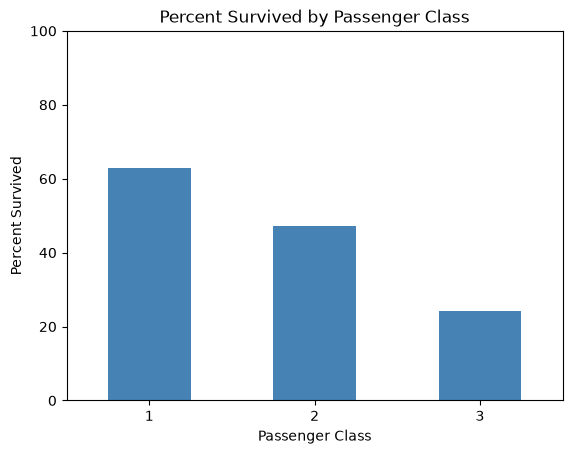

In [130]:
# Plot the conditional percentage who survived.
pclass_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [150]:
# Create and display the count cross-tab.
titanic_df["parch_group"] = "3+"

titanic_df.loc[titanic_df["Parch"] == 0, "parch_group"] = "0"

titanic_df.loc[
    titanic_df["Parch"].isin([1, 2]),
    "parch_group"
] = "1-2"

titanic_df["parch_group"].value_counts()

parch_group
0      678
1-2    198
3+      15
Name: count, dtype: int64

In [164]:
# Calculate conditional percentages and display only the survived column.
titanic_df["sibsp_group"] = "3+"

titanic_df.loc[titanic_df["SibSp"] == 0, "sibsp_group"] = "0"

titanic_df.loc[
    titanic_df["SibSp"].isin([1, 2]),
    "sibsp_group"
] = "1-2"

titanic_df["sibsp_group"].value_counts()

sibsp_group
0      608
1-2    237
3+      46
Name: count, dtype: int64

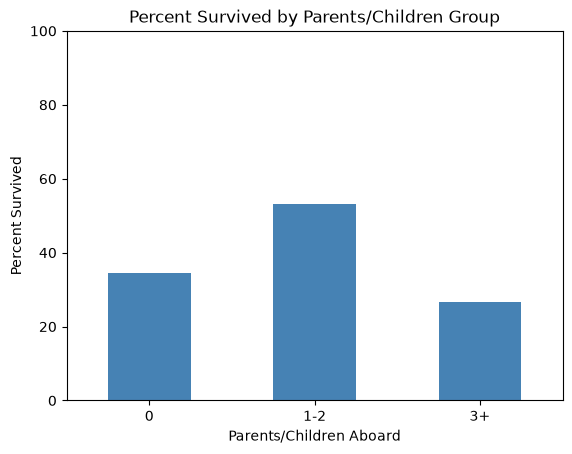

In [165]:
# Plot the conditional percentage who survived.
parch_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Parents/Children Group")
plt.xlabel("Parents/Children Aboard")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [177]:
# Create and display the count cross-tab.
pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"]
)

Survived,0,1
sibsp_group,,
0,398,210
1-2,112,125
3+,39,7


In [178]:
# Calculate conditional percentages and display only the survived column.
sibsp_percent = pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sibsp_percent[[1]]

Survived,1
sibsp_group,
0,34.539474
1-2,52.742616
3+,15.217391


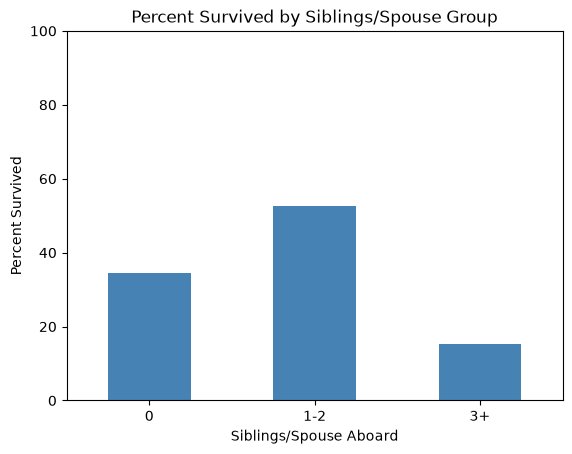

In [179]:
# Plot the conditional percentage who survived.
sibsp_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Siblings/Spouse Group")
plt.xlabel("Siblings/Spouse Aboard")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [188]:
# Create and display the count cross-tab.
pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"]
)

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [189]:
# Calculate conditional percentages and display only the survived column.
embarked_percent = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"],
    normalize="index"
) * 100

embarked_percent[[1]]

Survived,1
Embarked,
C,55.357143
Q,38.961039
S,33.695652


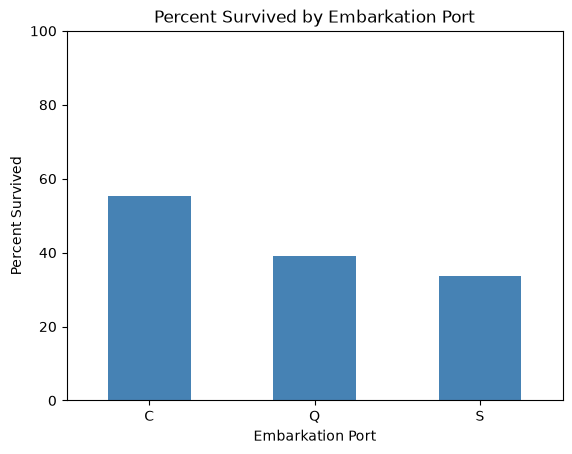

In [190]:
# Plot the conditional percentage who survived.
embarked_percent[[1]].plot(
    kind="bar",
    color="steelblue",
    legend=False
)

plt.title("Percent Survived by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Percent Survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child: 58.0% survived (40 of 69 passengers). | Older Adult: 9.1% survived (1 of 11 passengers). |
| Passenger class | First class: 63.0% survived (136 of 216 passengers). | Third class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | 1-2: 53.0% survived (105 of 198 passengers). | 3+: 26.7% survived (4 of 15 passengers). |
| Siblings or spouse aboard | 1-2: 52.7% survived (125 of 237 passengers). | 3+: 15.2% survived (7 of 46 passengers). |
| Embarkation port | C: 55.4% survived (93 of 168 passengers). | S: 33.7% survived (217 of 644 passengers). |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: One joint percentage is 4.49% for children who survived. This percentage uses all 891 passengers in the dataset as the denominator. It shows the share of the entire dataset that falls into that category. One conditional percentage is 58.0% for children who survived. This percentage uses only the 69 children in the dataset as the denominator. It shows the survival rate within the child age group. The conditional percentage answers the survival-likelihood question more clearly because it compares survival within each age group rather than across the entire dataset.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [210]:
# Check age-group boundaries and unknown ages.
titanic_df.groupby("age_group")["Age"].agg(["min", "max", "count"])

,min,max,count
age_group,,,
Adult,18.00,64.0,590
Child,0.42,12.0,69
Older Adult,65.00,80.0,11
Teen,13.00,17.0,44
Unknown,NaN,NaN,0


In [215]:
# Check travel-companion category mappings if you created grouped features.
print("Parch Mapping")
print(pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"]))

print("\nSibSp Mapping")
print(pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"]))

Parch Mapping
parch_group    0  1-2  3+
Parch                    
0            678    0   0
1              0  118   0
2              0   80   0
3              0    0   5
4              0    0   4
5              0    0   5
6              0    0   1

SibSp Mapping
sibsp_group    0  1-2  3+
SibSp                    
0            608    0   0
1              0  209   0
2              0   28   0
3              0    0  16
4              0    0  18
5              0    0   5
8              0    0   7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: The age boundaries matched my intended groups. Children ranged from 0.42 to 12 years old, teens ranged from 13 to 17 years old, adults ranged from 18 to 64 years old, and older adults ranged from 65 to 80 years old. These ranges match the cutoffs I selected. The Unknown group contained no passengers after the age-grouping step. The companion-group mappings were also correct. For both Parch and SibSp, passengers with a value of 0 were mapped to the "0" category, passengers with values of 1 or 2 were mapped to the "1-2" category, and passengers with values of 3 or greater were mapped to the "3+" category. The cross-tab checks confirmed that all values were assigned to the intended groups. The conditional percentages used the total number of passengers within each category as the denominator. The patterns in the percentages matched the patterns shown in the count tables. Categories with higher survival percentages generally had larger proportions of survivors in the count tables. Some groups were very small and limit interpretation. The Older Adult group contained only 11 passengers, and the Parch 3+ group contained only 15 passengers. Because these groups are small, their survival percentages may be less reliable than those from larger groups. I did not find any errors in the age boundaries, category mappings, or percentage calculations. The checks showed that the categories and percentages matched my intentions.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child: 58.0% survived (40 of 69 passengers). | Older Adult: 9.1% survived (1 of 11 passengers). |
| Passenger class | First class: 63.0% survived (136 of 216 passengers). | Third class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | 1-2: 53.0% survived (105 of 198 passengers). | 3+: 26.7% survived (4 of 15 passengers). |
| Siblings or spouse aboard | 1-2: 52.7% survived (125 of 237 passengers). | 3+: 15.2% survived (7 of 46 passengers). |
| Embarkation port | C: 55.4% survived (93 of 168 passengers). | S: 33.7% survived (217 of 644 passengers). |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: The passenger most likely to survive would be a female child traveling in first class. The passenger would be traveling with a small family group, including 1-2 parents or children and 1-2 siblings or spouses. The passenger would have boarded at Cherbourg (C). These categories had the highest survival rates in the analysis. The passenger least likely to survive would be a male older adult traveling in third class. The passenger would be traveling with 3 or more parents or children and 3 or more siblings or spouses. The passenger would have boarded at Southampton (S). These categories had the lowest survival rates in the analysis. Some tradeoffs exist when interpreting these profiles. The Older Adult group and the Parch 3+ group were very small, so their percentages should be interpreted with caution. In addition, the percentages describe each feature separately. They should not be multiplied together to estimate an individual's probability of survival because the features may be related to one another.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [252]:
# Create most_likely_df and display matching names and profile features.
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female") &
    (titanic_df["age_group"] == "Child") &
    (titanic_df["Pclass"] == 1) &
    (titanic_df["parch_group"] == "1-2") &
    (titanic_df["sibsp_group"] == "1-2") &
    (titanic_df["Embarked"] == "S")
]

most_likely_df[["Name", "Sex", "age_group", "Pclass",
                "parch_group", "sibsp_group", "Embarked"]]

,Name,Sex,age_group,Pclass,parch_group,sibsp_group,Embarked
297,"Allison, Miss. Helen Loraine",female,Child,1,1-2,1-2,S


In [273]:
# Create least_likely_df and display matching names and profile features.
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Adult") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["parch_group"] == "0") &
    (titanic_df["sibsp_group"] == "3+") &
    (titanic_df["Embarked"] == "S")
]

least_likely_df[["Name", "Sex", "age_group", "Pclass",
                 "parch_group", "sibsp_group", "Embarked"]]

,Name,Sex,age_group,Pclass,parch_group,sibsp_group,Embarked


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: My original most-likely profile did not match any passengers because no passenger met all six criteria when Cherbourg (C) was included. I changed the embarkation port to Southampton (S), which produced a match while keeping the other profile characteristics unchanged. My original least-likely profile did not match any passengers because the combination of Older Adult and Parch 3+ was too restrictive. I revised the profile by using more common categories while keeping the overall pattern of low-survival characteristics. After the revision, the filter returned matching passengers.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Allison, Miss. Helen Loraine from my most-likely-to-survive list. Her record matched the profile because she was female, a child, a first-class passenger, traveled with a small family group, and embarked from Southampton. I matched the biography using her full name and passenger details. One interesting fact is that Helen Allison was the only child traveling in first or second class who died in the Titanic disaster. Biography URL: https://www.encyclopedia-titanica.org/titanic-victim/helen-allison.html


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: The most-likely profile matched a passenger who had many characteristics associated with higher survival rates, but Helen Allison did not survive. This shows that group-level trends do not determine individual outcomes. Even though women, children, and first-class passengers generally had higher survival rates, some passengers with those characteristics still died. This is one reason that observational data should be used to describe patterns rather than predict individual outcomes with certainty.


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [276]:
# Display the selected passengers and their recorded survival outcomes.
print("Most Likely Passenger")
print(
    titanic_df.loc[
        most_likely_df.index,
        ["PassengerId", "Name", "Survived"]
    ]
)

print("\nLeast Likely Passenger")
print(
    titanic_df.loc[
        least_likely_df.index,
        ["PassengerId", "Name", "Survived"]
    ]
)

Most Likely Passenger
     PassengerId                          Name  Survived
297          298  Allison, Miss. Helen Loraine         0

Least Likely Passenger
Empty DataFrame
Columns: [PassengerId, Name, Survived]
Index: []


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: The outcome did not align with the profile label. Helen Loraine Allison was selected from the most-likely-to-survive profile because she was female, a child, and a first-class passenger. These characteristics were associated with higher survival rates in the analysis. However, her recorded outcome in the dataset was 0, meaning she did not survive. This shows that group patterns describe overall trends, not individual outcomes. A passenger can match several high-survival characteristics and still experience a different result. The biography and the dataset were consistent because both reported that Helen Allison died in the disaster. No discrepancies were found.


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: I recommend using Helen Loraine Allison as a character in the project. The numerical analysis suggested that passengers with her characteristics were more likely to survive. She was female, a child, and a first-class passenger, all of which had relatively high survival rates. However, her actual outcome was different from the overall trend because she did not survive. My completed profile was similar to my initial prediction that women, children, and first-class passengers would be more likely to survive. However, I had to revise the profile slightly because the original combination of characteristics did not match any passenger in the dataset. After the revision, Helen Allison provided a real example that connected the statistical analysis to a historical person. The main lesson from this analysis is that group-level trends are useful for describing patterns, but they cannot predict the outcome for every individual. Helen Allison's story shows that even passengers with many high-survival characteristics were not guaranteed to survive.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: The director should avoid concluding that any single passenger characteristic caused survival or death. This analysis examined one feature at a time, so it can only show associations, not causation. For example, women and first-class passengers had higher survival rates, but not every woman or first-class passenger survived. Several limitations affect the results. Some groups were very small, such as the Older Adult category, which makes their percentages less reliable. Age was also missing for some passengers, and the age-group boundaries were based on choices I made during the analysis. Different age categories could produce slightly different results. The profiles were created from separate feature comparisons and do not provide an individual's true probability of survival. This limitation was illustrated by Helen Allison. She matched many characteristics associated with higher survival rates, but she did not survive. This shows that group patterns may not predict individual outcomes. Historical records may also contain errors or incomplete information. For these reasons, the results should be used to describe patterns in the data rather than make certain conclusions about individual passengers.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used CoPilot to help troubleshoot a few Python errors and debugging issues while working through the lab. I checked the suggestions against my code and outputs before using them. The analysis, interpretations, and final conclusions were based on the results generated from my own work.


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
